# 任务六：VaR 的覆盖率检验与独立性检验

本 notebook 从综合任务中单独抽取任务六，并保留完成任务所必需的数据生成、模型拟合和滚动预测信息。统一设定为：

- $X_t\overset{iid}{\sim}\mathrm{Gamma}(2,100)$，共 3650 天；
- 置信水平 $\alpha=0.95$，理论超出概率 $p=1-\alpha=0.05$；
- 使用长度为 1825 天的滚动窗口，产生 1825 个一步向前 VaR 预测；
- 比较真实 Gamma、Gamma 矩估计、Lognormal 极大似然和 Pareto-PWM；
- 随机种子固定为 `20260918`。

## 必要准备

以下内容只用于生成四组 VaR 预测，供五个小问共同使用。

## 必要的模型与预测公式

对每个滚动窗口，三种拟合方法为：

$$
\hat k=\frac{\bar X^2}{s^2},\qquad
\hat\theta=\frac{s^2}{\bar X},
$$

$$
\hat\mu=\frac1n\sum_{i=1}^n\log X_i,\qquad
\hat\sigma^2=\frac1n\sum_{i=1}^n(\log X_i-\hat\mu)^2,
$$

对 Type-I Pareto，令概率加权矩
$\beta_0=E[X]$、$\beta_1=E[XF(X)]$，样本估计为

$$
\hat\beta_0=\bar X,\qquad
\hat\beta_1=\frac1n\sum_{i=1}^n\frac{i-1}{n-1}X_{(i)}.
$$

由 $\lambda_1=\beta_0$、$\lambda_2=2\beta_1-\beta_0$ 和
$\tau=\lambda_2/\lambda_1=1/(2a-1)$，得到

$$
\hat a=\frac{1+\hat\tau}{2\hat\tau},\qquad
\hat x_m=\hat\beta_0\frac{\hat a-1}{\hat a}.
$$

对应的一步向前 VaR 为

$$
\begin{aligned}
v^{G}_{t+1|t}&=F^{-1}_{\Gamma(\hat k_t,\hat\theta_t)}(\alpha),\\
v^{LN}_{t+1|t}&=\exp(\hat\mu_t+\hat\sigma_t\Phi^{-1}(\alpha)),\\
v^{P}_{t+1|t}&=\hat x_{m,t}(1-\alpha)^{-1/\hat a_t}.
\end{aligned}
$$

所有参数只使用预测日之前的 1825 个观测估计，因此不存在前视偏差。

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 20260918
alpha = 0.95
p = 1 - alpha
n_days = 3650
window = 1825
true_k, true_theta = 2.0, 100.0

pd.set_option("display.float_format", lambda z: f"{z:,.6f}")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

rng = np.random.default_rng(SEED)
x = rng.gamma(shape=true_k, scale=true_theta, size=n_days)
true_var = stats.gamma(a=true_k, scale=true_theta).ppf(alpha)

def fit_var_forecasts(data):
    rows = []
    for t in range(window, len(data)):
        w = data[t-window:t]
        mean = w.mean()
        var = w.var(ddof=1)

        gamma_k = mean**2 / var
        gamma_theta = var / mean
        gamma_var = stats.gamma(a=gamma_k, scale=gamma_theta).ppf(alpha)

        log_w = np.log(w)
        log_mu = log_w.mean()
        log_sigma = log_w.std(ddof=0)
        lognormal_var = np.exp(log_mu + log_sigma * stats.norm.ppf(alpha))

        ordered = np.sort(w)
        n = len(ordered)
        beta0 = mean
        beta1 = np.sum((np.arange(n)/(n-1))*ordered)/n
        l2 = 2*beta1-beta0
        lcv = l2/beta0
        pareto_a = (1+lcv)/(2*lcv)
        pareto_xm = beta0*(pareto_a-1)/pareto_a
        pareto_var = pareto_xm * (1-alpha)**(-1/pareto_a)

        rows.extend([
            (t, "Gamma", gamma_var, data[t]),
            (t, "Lognormal", lognormal_var, data[t]),
            (t, "Pareto-PWM", pareto_var, data[t]),
        ])
    return pd.DataFrame(rows, columns=["t", "模型", "VaR", "Y"])

pred = fit_var_forecasts(x)
y_oos = x[window:]

display(pd.DataFrame({
    "项目": ["样本天数", "滚动窗长度", "预测期数", "alpha", "理论超出概率", "真实VaR"],
    "数值": [n_days, window, len(y_oos), alpha, p, true_var],
}))
display(pred.groupby("模型")["VaR"].agg(["mean", "min", "max"]))

# 诊断：旧实现把样本最小值当作尺度，仅用于展示错误来源，不参与后续回测。
first_window = x[:window]
old_xm = first_window.min()
old_a = first_window.mean()/(first_window.mean()-old_xm)
old_var = old_xm*(1-alpha)**(-1/old_a)
new_first_var = pred.loc[pred["模型"].eq("Pareto-PWM"), "VaR"].iloc[0]
display(pd.DataFrame({
    "方案": ["旧：xmin+均值匹配（错误）", "新：PWM/L-moment"],
    "首窗VaR": [old_var, new_first_var],
    "相对真实VaR": [old_var/true_var, new_first_var/true_var],
}))

,项目,数值
0,样本天数,"3,650.000000"
1,滚动窗长度,"1,825.000000"
2,预测期数,"1,825.000000"
3,alpha,0.950000
4,理论超出概率,0.050000
5,真实VaR,474.386452


,mean,min,max
模型,,,
Gamma,474.104982,461.803557,493.921144
Lognormal,588.720126,575.501796,600.729947
Pareto-PWM,463.312411,455.010811,477.810089


,方案,首窗VaR,相对真实VaR
0,旧：xmin+均值匹配（错误）,10.722726,0.022603
1,新：PWM/L-moment,466.368655,0.983099


## 小问 1

> 构造命中序列 $I_t=1\{Y_t>v_t\}$，报告三个模型与真实 VaR 的超出次数与覆盖频率。

### 回答

先给出三个待回测模型的定义。对第 $t$ 个滚动窗口中的样本
$X_{t-n+1},\ldots,X_t$，其中 $n=1825$：

**1. Gamma 矩估计法**

由 $E[X]=k\theta$、$\operatorname{Var}(X)=k\theta^2$ 得

$$
\hat k_t=\frac{\bar X_t^2}{s_t^2},\qquad
\hat\theta_t=\frac{s_t^2}{\bar X_t},\qquad
v_{t+1|t}^{G}=F_{\Gamma(\hat k_t,\hat\theta_t)}^{-1}(\alpha).
$$

**2. Lognormal 极大似然法**

令 $\log X\sim N(\mu,\sigma^2)$，则

$$
\hat\mu_t=\frac1n\sum_{i=1}^n\log X_i,\qquad
\hat\sigma_t^2=\frac1n\sum_{i=1}^n(\log X_i-\hat\mu_t)^2,
$$

$$
v_{t+1|t}^{LN}=\exp\!\left[\hat\mu_t+hat\sigma_t\Phi^{-1}(\alpha)\right].
$$

**3. Type-I Pareto PWM/L-moment 法**

对次序统计量 $X_{(1)}\le\cdots\le X_{(n)}$，定义

$$
\hat\beta_{0,t}=\bar X_t,\qquad
\hat\beta_{1,t}=\frac1n\sum_{i=1}^n\frac{i-1}{n-1}X_{(i)},\qquad
\hat\tau_t=\frac{2\hat\beta_{1,t}-\hat\beta_{0,t}}{\hat\beta_{0,t}}.
$$

于是

$$
\hat a_t=\frac{1+\hat\tau_t}{2\hat\tau_t},\qquad
\hat x_{m,t}=\hat\beta_{0,t}\frac{\hat a_t-1}{\hat a_t},\qquad
v_{t+1|t}^{P}=\hat x_{m,t}(1-\alpha)^{-1/\hat a_t}.
$$

此外，以已知生成分布计算的
$v^{\mathrm{True}}=F_{\Gamma(2,100)}^{-1}(0.95)$ 作为真值基准。

得到四组 VaR 序列后，对模型 $m$ 定义命中序列

$$I_t^{(m)}=\mathbf 1\{Y_t>v_t^{(m)}\},\qquad
N_m=\sum_{t=1}^n I_t^{(m)},\qquad
\hat p_m=\frac{N_m}{n}.$$

其中 $\hat p_m$ 是超出频率。对应的经验覆盖频率为

$$
\widehat C_m=\frac1n\sum_{t=1}^n\mathbf 1\{Y_t\le v_t^{(m)}\}
=1-\hat p_m.
$$

正确的 95% VaR 模型应使超出频率 $\hat p_m$ 接近 5%，同时使覆盖频率
$\widehat C_m$ 接近 $\alpha=95\%$。

,模型,预测期数,超出次数,超出频率,覆盖次数,覆盖频率,理论覆盖频率,覆盖频率偏差
0,True-Gamma,1825,95,0.052055,1730,0.947945,0.950000,-0.002055
1,Gamma,1825,94,0.051507,1731,0.948493,0.950000,-0.001507
2,Lognormal,1825,40,0.021918,1785,0.978082,0.950000,0.028082
3,Pareto-PWM,1825,103,0.056438,1722,0.943562,0.950000,-0.006438


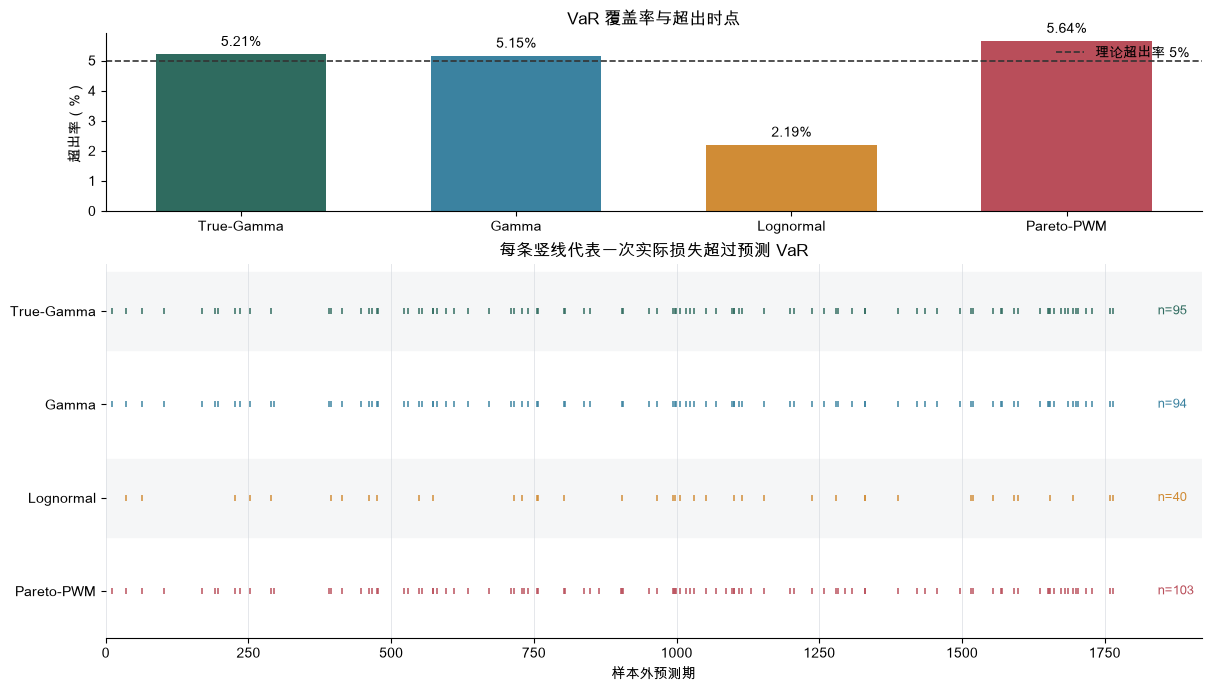

In [2]:
models = {"True-Gamma": (np.full(window, true_var), y_oos)}
for name, group in pred.groupby("模型", sort=False):
    models[name] = (group["VaR"].to_numpy(), group["Y"].to_numpy())

hit_dict = {
    name: (realized > var_forecast).astype(int)
    for name, (var_forecast, realized) in models.items()
}
coverage = pd.DataFrame([
    [name, len(hit), int(hit.sum()), hit.mean(),
     len(hit)-int(hit.sum()), 1-hit.mean(), alpha, (1-hit.mean())-alpha]
    for name, hit in hit_dict.items()
], columns=[
    "模型", "预测期数", "超出次数", "超出频率",
    "覆盖次数", "覆盖频率", "理论覆盖频率", "覆盖频率偏差",
])
display(coverage)

colors = {
    "True-Gamma": "#2F6B5F", "Gamma": "#3B82A0",
    "Lognormal": "#D08C36", "Pareto-PWM": "#B94E5A",
}
names = list(hit_dict)
frequencies = np.array([hit_dict[name].mean() for name in names])
fig = plt.figure(figsize=(12, 6.8), constrained_layout=True)
grid = fig.add_gridspec(2, 1, height_ratios=[1.05, 2.2])

ax_rate = fig.add_subplot(grid[0])
bars = ax_rate.bar(names, frequencies*100, color=[colors[n] for n in names], width=0.62)
ax_rate.axhline(p*100, color="#333333", linestyle="--", linewidth=1.2, label="理论超出率 5%")
for bar, frequency in zip(bars, frequencies):
    ax_rate.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.18,
                 f"{frequency:.2%}", ha="center", va="bottom", fontsize=10)
ax_rate.set_ylabel("超出率（%）")
ax_rate.set_title("VaR 覆盖率与超出时点")
ax_rate.spines[["top", "right"]].set_visible(False)
ax_rate.legend(frameon=False, loc="upper right")

ax_hits = fig.add_subplot(grid[1])
for row, name in enumerate(names):
    hit = hit_dict[name]
    locations = np.flatnonzero(hit)
    ax_hits.axhspan(row-0.42, row+0.42, color="#F5F6F7" if row % 2 == 0 else "white", zorder=0)
    ax_hits.scatter(locations, np.full(len(locations), row), s=18, marker="|",
                    linewidths=1.2, color=colors[name], alpha=0.9)
    ax_hits.text(len(hit)+18, row, f"n={hit.sum()}", va="center", color=colors[name], fontsize=9)
ax_hits.set_yticks(range(len(names)), names)
ax_hits.set_ylim(len(names)-0.5, -0.5)
ax_hits.set_xlim(0, len(y_oos)+95)
ax_hits.set_xlabel("样本外预测期")
ax_hits.set_title("每条竖线代表一次实际损失超过预测 VaR")
ax_hits.grid(axis="x", color="#D9DDE2", linewidth=0.7, alpha=0.7)
ax_hits.spines[["top", "right", "left"]].set_visible(False)
plt.show()

## 小问 2

> 作 Kupiec 无条件覆盖检验、Christoffersen 独立性检验与条件覆盖检验，并分解条件覆盖统计量。

### 回答

三种检验使用同一命中序列，但检验的性质不同：

| 检验 | 检验对象 | 原假设 | 自由度 |
|---|---|---|---:|
| Kupiec 无条件覆盖检验 | 超出比例是否正确 | $P(I_t=1)=p=1-\alpha$ | 1 |
| Christoffersen 独立性检验 | 超出是否存在一阶聚集 | $P(I_t=1\mid I_{t-1}=0)=P(I_t=1\mid I_{t-1}=1)$ | 1 |
| 条件覆盖检验 | 覆盖率正确且超出相互独立 | 同时满足正确覆盖与独立性 | 2 |

#### 2.1 Kupiec 无条件覆盖检验

令 $x=\sum_{t=1}^n I_t$、$\hat p=x/n$。需要检验

$$H_0:p=1-\alpha=0.05,\qquad H_1:p\ne0.05.$$

似然比统计量为

$$
LR_{uc}=-2\log\frac{(1-p)^{n-x}p^x}
{(1-\hat p)^{n-x}\hat p^x}
\overset{a}{\sim}\chi_1^2.
$$

该检验只看总超出次数，不使用超出的时间顺序。若 p 值小于 0.05，则拒绝“覆盖率正确”。

#### 2.2 Christoffersen 独立性检验

记 $n_{ij}$ 为 $I_{t-1}=i,I_t=j$ 的转移次数，并定义

$$
\hat\pi_0=\frac{n_{01}}{n_{00}+n_{01}},\qquad
\hat\pi_1=\frac{n_{11}}{n_{10}+n_{11}},\qquad
\hat\pi=\frac{n_{01}+n_{11}}{n-1}.
$$

检验假设为

$$H_0:\pi_0=\pi_1\quad\text{（一阶独立）},qquad
H_1:\pi_0\ne\pi_1\quad\text{（存在一阶依赖）}.$$

其似然比统计量为

$$
LR_{ind}=-2\log
\frac{(1-\hat\pi)^{n_{00}+n_{10}}\hat\pi^{n_{01}+n_{11}}}
{(1-\hat\pi_0)^{n_{00}}\hat\pi_0^{n_{01}}
(1-\hat\pi_1)^{n_{10}}\hat\pi_1^{n_{11}}}
\overset{a}{\sim}\chi_1^2.
$$

该检验不要求超出率等于 5%，只判断超出是否具有一阶聚集。若 p 值小于 0.05，则拒绝独立性。

#### 2.3 Christoffersen 条件覆盖检验

条件覆盖检验联合考察前两项条件：

$$
H_0:\quad P(I_t=1)=0.05\quad\text{且}\quad I_t\text{ 一阶独立}.
$$

由于两个似然比部分可加，

$$LR_{cc}=LR_{uc}+LR_{ind}\overset{a}{\sim}\chi_2^2.$$

若 p 值小于 0.05，则说明“覆盖率正确”和“独立性”至少有一项不成立。分解时：

$$
\underbrace{LR_{cc}}_{\text{条件覆盖总偏离}}
=\underbrace{LR_{uc}}_{\text{覆盖率偏离}}
+\underbrace{LR_{ind}}_{\text{时间依赖偏离}}.
$$

因此，比较 $LR_{uc}/LR_{cc}$ 与 $LR_{ind}/LR_{cc}$，可以判断总统计量主要来自覆盖率错误还是超出聚集。两部分各服从渐近 $\chi_1^2$，总统计量服从渐近 $\chi_2^2$。

In [3]:
def kupiec_lr(hit, p=p):
    hit = np.asarray(hit, dtype=int)
    n = len(hit)
    x_count = int(hit.sum())
    phat = x_count / n
    ll_null = x_count*np.log(p) + (n-x_count)*np.log(1-p)
    if x_count in (0, n):
        ll_alt = 0.0
    else:
        ll_alt = x_count*np.log(phat) + (n-x_count)*np.log(1-phat)
    lr = 2*(ll_alt-ll_null)
    return lr, stats.chi2.sf(lr, 1), x_count, phat

def christoffersen_lr(hit):
    hit = np.asarray(hit, dtype=int)
    n00 = n01 = n10 = n11 = 0
    for previous, current in zip(hit[:-1], hit[1:]):
        if previous == 0 and current == 0: n00 += 1
        elif previous == 0 and current == 1: n01 += 1
        elif previous == 1 and current == 0: n10 += 1
        else: n11 += 1

    pi = (n01+n11)/(n00+n01+n10+n11)
    pi0 = n01/(n00+n01) if n00+n01 else 0
    pi1 = n11/(n10+n11) if n10+n11 else 0

    def log_term(count, probability):
        if count == 0:
            return 0.0
        probability = np.clip(probability, 1e-12, 1-1e-12)
        return count*np.log(probability)

    ll_independent = log_term(n01+n11, pi) + log_term(n00+n10, 1-pi)
    ll_markov = (log_term(n01, pi0) + log_term(n00, 1-pi0)
                 + log_term(n11, pi1) + log_term(n10, 1-pi1))
    lr = 2*(ll_markov-ll_independent)
    return lr, stats.chi2.sf(lr, 1), (n00, n01, n10, n11)

from IPython.display import Markdown

kupiec_rows = []
independence_rows = []
conditional_rows = []
for name, hit in hit_dict.items():
    lr_uc, p_uc, count, frequency = kupiec_lr(hit)
    lr_ind, p_ind, transitions = christoffersen_lr(hit)
    n00, n01, n10, n11 = transitions
    pi0 = n01/(n00+n01) if n00+n01 else np.nan
    pi1 = n11/(n10+n11) if n10+n11 else np.nan
    lr_cc = lr_uc + lr_ind
    p_cc = stats.chi2.sf(lr_cc, 2)
    uc_share = lr_uc/lr_cc if lr_cc > 0 else np.nan
    ind_share = lr_ind/lr_cc if lr_cc > 0 else np.nan
    main_source = "覆盖率偏离" if lr_uc >= lr_ind else "时间依赖偏离"

    kupiec_rows.append([
        name, len(hit), len(hit)*p, count, frequency,
        lr_uc, p_uc, "不拒绝正确覆盖" if p_uc >= 0.05 else "拒绝正确覆盖",
    ])
    independence_rows.append([
        name, n00, n01, n10, n11, pi0, pi1,
        lr_ind, p_ind, "不拒绝独立性" if p_ind >= 0.05 else "拒绝独立性",
    ])
    conditional_rows.append([
        name, lr_uc, lr_ind, lr_cc, lr_cc-lr_uc-lr_ind,
        uc_share, ind_share, main_source, p_cc,
        "不拒绝条件覆盖" if p_cc >= 0.05 else "拒绝条件覆盖",
    ])

kupiec_table = pd.DataFrame(kupiec_rows, columns=[
    "模型", "预测期数n", "理论超出次数np", "实际超出次数", "超出频率",
    "LR_uc", "p值", "5%水平结论",
])
independence_table = pd.DataFrame(independence_rows, columns=[
    "模型", "n00", "n01", "n10", "n11", "pi0=P(1|0)", "pi1=P(1|1)",
    "LR_ind", "p值", "5%水平结论",
])
conditional_table = pd.DataFrame(conditional_rows, columns=[
    "模型", "覆盖率部分LR_uc", "独立性部分LR_ind", "总统计量LR_cc",
    "分解核验误差", "覆盖率贡献占比", "独立性贡献占比", "主要来源",
    "p值(df=2)", "5%水平结论",
])

display(Markdown("#### 表 2.1 Kupiec 无条件覆盖检验：检验超出率是否为 5%"))
display(kupiec_table)
display(Markdown("#### 表 2.2 Christoffersen 独立性检验：检验超出是否一阶聚集"))
display(independence_table)
display(Markdown("#### 表 2.3 Christoffersen 条件覆盖检验：联合检验正确覆盖与独立性"))
display(conditional_table)
display(Markdown(
    "**读表方法：** `分解核验误差` 应为 0；贡献占比之和应为 1。"
    "若条件覆盖被拒绝，可结合 `主要来源` 和前两张表判断拒绝原因。"
))

#### 表 2.1 Kupiec 无条件覆盖检验：检验超出率是否为 5%

,模型,预测期数n,理论超出次数np,实际超出次数,超出频率,LR_uc,p值,5%水平结论
0,True-Gamma,1825,91.250000,95,0.052055,0.160158,0.689011,不拒绝正确覆盖
1,Gamma,1825,91.250000,94,0.051507,0.086421,0.768778,不拒绝正确覆盖
2,Lognormal,1825,91.250000,40,0.021918,38.022367,0.000000,拒绝正确覆盖
3,Pareto-PWM,1825,91.250000,103,0.056438,1.531768,0.215847,不拒绝正确覆盖


#### 表 2.2 Christoffersen 独立性检验：检验超出是否一阶聚集

,模型,n00,n01,n10,n11,pi0=P(1|0),pi1=P(1|1),LR_ind,p值,5%水平结论
0,True-Gamma,1637,92,92,3,0.053210,0.031579,0.979693,0.322275,不拒绝独立性
1,Gamma,1639,91,91,3,0.052601,0.031915,0.891312,0.345122,不拒绝独立性
2,Lognormal,1745,39,39,1,0.021861,0.025000,0.017223,0.895589,不拒绝独立性
3,Pareto-PWM,1621,100,100,3,0.058106,0.029126,1.826890,0.176495,不拒绝独立性


#### 表 2.3 Christoffersen 条件覆盖检验：联合检验正确覆盖与独立性

,模型,覆盖率部分LR_uc,独立性部分LR_ind,总统计量LR_cc,分解核验误差,覆盖率贡献占比,独立性贡献占比,主要来源,p值(df=2),5%水平结论
0,True-Gamma,0.160158,0.979693,1.139851,0.000000,0.140508,0.859492,时间依赖偏离,0.565568,不拒绝条件覆盖
1,Gamma,0.086421,0.891312,0.977733,0.000000,0.088389,0.911611,时间依赖偏离,0.613321,不拒绝条件覆盖
2,Lognormal,38.022367,0.017223,38.039589,0.000000,0.999547,0.000453,覆盖率偏离,0.000000,拒绝条件覆盖
3,Pareto-PWM,1.531768,1.826890,3.358658,0.000000,0.456066,0.543934,时间依赖偏离,0.186499,不拒绝条件覆盖


**读表方法：** `分解核验误差` 应为 0；贡献占比之和应为 1。若条件覆盖被拒绝，可结合 `主要来源` 和前两张表判断拒绝原因。

## 小问 3

> 用超出段数与独立假设下的期望段数作直观对照。

### 回答

把连续的一次或多次超出视为一个“超出段”。实际段数为

$$R=\sum_{t=1}^n\mathbf 1\{I_t=1,I_{t-1}=0\}.$$

独立假设下，无条件期望约为 $np(1-p)$；给定实际超出次数 $N$ 后，也可用
$N(1-p)$ 作条件式参照。实际段数明显偏少通常表示超出集中成簇。

In [4]:
segment_rows = []
for name, hit in hit_dict.items():
    count = int(hit.sum())
    segments = int(np.sum((hit == 1) & np.r_[True, hit[:-1] == 0]))
    segment_rows.append([
        name, count, segments, len(hit)*p*(1-p), count*(1-p),
        segments-count*(1-p),
    ])
display(pd.DataFrame(segment_rows, columns=[
    "模型", "超出次数", "实际超出段数", "无条件期望段数",
    "按实际次数的期望段数", "实际段数-条件期望",
]))

,模型,超出次数,实际超出段数,无条件期望段数,按实际次数的期望段数,实际段数-条件期望
0,True-Gamma,95,92,86.687500,90.250000,1.750000
1,Gamma,94,91,86.687500,89.300000,1.700000
2,Lognormal,40,39,86.687500,38.000000,1.000000
3,Pareto-PWM,103,100,86.687500,97.850000,2.150000


## 小问 4

> 用蒙特卡洛给出有限样本规模，用两状态马尔可夫链给出独立性检验对聚类的检验力。

### 回答
### 1. 有限样本规模的定义

设检验统计量为 $T_n$，显著性水平为 $\gamma=0.05$，拒绝域为
$\mathcal R_\gamma$。检验在样本量 $n$ 下的真实规模定义为

$$
s_n=P_{H_0}(T_n\in\mathcal R_\gamma).
$$

渐近卡方临界值只保证 $n\to\infty$ 时 $s_n\to\gamma$；在本题有限样本
$n=1825$ 下，实际拒绝概率可能不恰好等于 5%。因此在原假设下生成
$B$ 条独立命中序列，并以拒绝指示变量

$$R_b=\mathbf 1\{p\text{-value}_b<\gamma\}$$

记录第 $b$ 次模拟是否拒绝。经验规模及其蒙特卡洛标准误为

$$
\widehat s_n=\frac1B\sum_{b=1}^B R_b,
\qquad
\operatorname{MCSE}(\widehat s_n)
=\sqrt{\frac{\widehat s_n(1-\widehat s_n)}{B}}.
$$

本题的规模实验使用正确模型下的
$I_t\overset{iid}{\sim}\operatorname{Bernoulli}(p)$，其中
$p=1-\alpha=0.05$。若检验校准良好，$\widehat s_n$ 应在考虑 MCSE 后接近 0.05。

### 2. 检验力的定义

对特定备择分布 $H_1$，有限样本检验力为

$$
\beta_n(H_1)=P_{H_1}(T_n\in\mathcal R_\gamma),
$$

其模拟估计与标准误同理为

$$
\widehat\beta_n=\frac1B\sum_{b=1}^B R_b,
\qquad
\operatorname{MCSE}(\widehat\beta_n)
=\sqrt{\frac{\widehat\beta_n(1-\widehat\beta_n)}{B}}.
$$

规模回答“模型正确时误报多少”，检验力回答“给定错误确实存在时能发现多少”；二者不能混为一谈。

### 3. 保持边际覆盖率不变的 Markov 聚类备择

令命中序列服从两状态一阶 Markov 链，转移矩阵为

$$
P=
\begin{pmatrix}
1-p_{01} & p_{01}\\
1-p_{11} & p_{11}
\end{pmatrix},
\qquad
p_{ij}=P(I_t=j\mid I_{t-1}=i).
$$

若平稳超出概率为 $\pi=P(I_t=1)$，平稳方程给出

$$
\pi=(1-\pi)p_{01}+\pi p_{11},
$$

从而

$$
\pi=\frac{p_{01}}{p_{01}+1-p_{11}},
\qquad
p_{01}=\frac{\pi(1-p_{11})}{1-\pi}.
$$

取 $\pi=p=0.05$、$p_{11}=0.40$，得到

$$P(I_t=1\mid I_{t-1}=1)=p_{11}=0.40,\qquad
p_{01}=\frac{p(1-p_{11})}{1-p}\approx0.03158.$$

于是该备择与原假设具有相同的 5% 边际超出率，但
$P(I_t=1\mid I_{t-1}=1)=40\%$ 远高于 5%，形成明显聚类。这样避免把
“覆盖率错误”与“时间依赖”混在一起，能够更纯粹地考察独立性检验的检验力。

### 4. 三种检验的理论预期

- Kupiec 检验只使用总超出次数。在边际超出率仍为 5% 时，它并非专门针对聚类设计；但 Markov 相关性会改变总次数的方差，所以其拒绝概率仍可能高于名义水平。
- Christoffersen 独立性检验直接比较 $p_{01}$ 与 $p_{11}$，因此应对上述强聚类具有较高检验力。
- 条件覆盖检验包含独立性部分 $LR_{ind}$，所以通常也具有较高检验力；但它使用两个自由度，在较弱备择下可能不如专门的独立性检验敏感。

In [5]:
def monte_carlo_size(B=1000, n=window, p=p):
    simulation_rng = np.random.default_rng(SEED+30)
    reject_uc = reject_ind = reject_cc = 0
    for _ in range(B):
        hit = simulation_rng.binomial(1, p, n)
        lr_uc, p_uc, *_ = kupiec_lr(hit, p)
        lr_ind, p_ind, *_ = christoffersen_lr(hit)
        reject_uc += p_uc < 0.05
        reject_ind += p_ind < 0.05
        reject_cc += stats.chi2.sf(lr_uc+lr_ind, 2) < 0.05
    return np.array([reject_uc, reject_ind, reject_cc])/B

def markov_power(B=1000, n=window, p=p, p11=0.40):
    simulation_rng = np.random.default_rng(SEED+31)
    p01 = p*(1-p11)/(1-p)
    reject_uc = reject_ind = reject_cc = 0
    stationary_p = p01/(p01+1-p11)
    for _ in range(B):
        hit = np.zeros(n, dtype=int)
        hit[0] = simulation_rng.binomial(1, stationary_p)
        for t in range(1, n):
            hit[t] = simulation_rng.binomial(1, p11 if hit[t-1] else p01)
        lr_uc, p_uc, *_ = kupiec_lr(hit, p)
        lr_ind, p_ind, *_ = christoffersen_lr(hit)
        reject_uc += p_uc < 0.05
        reject_ind += p_ind < 0.05
        reject_cc += stats.chi2.sf(lr_uc+lr_ind, 2) < 0.05
    return np.array([reject_uc, reject_ind, reject_cc])/B, stationary_p, p01

B = 1000
sizes = monte_carlo_size(B=B)
powers, stationary_p, p01 = markov_power(B=B)
test_names = ["Kupiec 无条件覆盖", "Christoffersen 独立性", "条件覆盖"]
rows = []
for test_name, estimate in zip(test_names, sizes):
    rows.append(["经验规模", test_name, "iid Bernoulli，p=5%", 0.05,
                 estimate, np.sqrt(estimate*(1-estimate)/B)])
for test_name, estimate in zip(test_names, powers):
    rows.append(["经验检验力", test_name, f"Markov聚类，平稳p={stationary_p:.2%}", np.nan,
                 estimate, np.sqrt(estimate*(1-estimate)/B)])

size_power_table = pd.DataFrame(rows, columns=[
    "指标", "检验", "数据生成机制", "名义水平", "蒙特卡洛估计", "蒙特卡洛标准误",
])
display(Markdown("#### 表 4.1 有限样本规模与聚类备择下的检验力"))
display(size_power_table)
display(pd.DataFrame({
    "Markov参数": ["p01=P(1|0)", "p11=P(1|1)", "平稳超出概率"],
    "数值": [p01, 0.40, stationary_p],
}))
display(Markdown(
    f"**结果解释。** 在 $B={B}$ 次模拟中，三种检验的经验规模分别为 "
    f"{sizes[0]:.1%}、{sizes[1]:.1%} 和 {sizes[2]:.1%}，均接近名义水平 5%。"
    f"在保持边际超出率为 5% 的强聚类备择下，Kupiec 检验力为 {powers[0]:.1%}，"
    f"独立性检验和条件覆盖检验的检验力分别为 {powers[1]:.1%} 和 {powers[2]:.1%}。"
    "这说明 Kupiec 检验并非识别聚类的主要工具；独立性统计量才直接利用转移结构。"
))

#### 表 4.1 有限样本规模与聚类备择下的检验力

,指标,检验,数据生成机制,名义水平,蒙特卡洛估计,蒙特卡洛标准误
0,经验规模,Kupiec 无条件覆盖,iid Bernoulli，p=5%,0.050000,0.052000,0.007021
1,经验规模,Christoffersen 独立性,iid Bernoulli，p=5%,0.050000,0.054000,0.007147
2,经验规模,条件覆盖,iid Bernoulli，p=5%,0.050000,0.054000,0.007147
3,经验检验力,Kupiec 无条件覆盖,Markov聚类，平稳p=5.00%,NaN,0.177000,0.012069
4,经验检验力,Christoffersen 独立性,Markov聚类，平稳p=5.00%,NaN,1.000000,0.000000
5,经验检验力,条件覆盖,Markov聚类，平稳p=5.00%,NaN,1.000000,0.000000


,Markov参数,数值
0,p01=P(1|0),0.031579
1,p11=P(1|1),0.400000
2,平稳超出概率,0.050000


**结果解释。** 在 $B=1000$ 次模拟中，三种检验的经验规模分别为 5.2%、5.4% 和 5.4%，均接近名义水平 5%。在保持边际超出率为 5% 的强聚类备择下，Kupiec 检验力为 17.7%，独立性检验和条件覆盖检验的检验力分别为 100.0% 和 100.0%。这说明 Kupiec 检验并非识别聚类的主要工具；独立性统计量才直接利用转移结构。

## 小问 5

> 覆盖率和独立性检验都通过，能否保证 ES 也可用？

### 回答

不能。覆盖率检验和独立性检验只使用二元命中序列 $I_t$，分别检查超出概率是否接近 5% 以及超出是否聚集，却舍弃了每次超出的损失幅度。模型完全可能正确预测“超过 VaR 的概率”，同时严重高估或低估超过 VaR 后的平均损失。

因此，通过两项 VaR 回测只是必要的诊断信号，不是 ES 正确性的充分条件。

### 如何判断 ES 是否可用

严格来说，有限样本中的任何统计检验都不能“保证”ES 一定正确，只能在给定显著性水平和检验力下提供支持证据。较可靠的做法是同时满足以下几层验证。

#### 1. 联合校准 VaR 与 ES

设模型在时点 $t$ 给出的预测为 $(v_t,e_t)$。正确预测至少应满足

$$
E\!\left[\mathbf 1\{Y_t>v_t\}-(1-\alpha)\mid\mathcal F_{t-1}\right]=0,
$$

以及连续分布下的尾部矩条件

$$
E\!\left[(Y_t-v_t)_+-(1-\alpha)(e_t-v_t)
\mid\mathcal F_{t-1}\right]=0.
$$

第一式检查 VaR 覆盖，第二式检查超过 VaR 后的平均损失是否与 ES 匹配。应对第二个残差的样本均值、显著性和时间相关性进行检验；仅检查第一式是不够的。

#### 2. 使用严格一致的联合评分函数

VaR 与 ES 可以联合评价。本文采用的 AL 型评分为

$$
S(v,e;y)=\log e+\frac{v}{e}
+\frac{(y-v)_+}{(1-\alpha)e}.
$$

在总体期望意义下，该评分在
$(v,e)=(\operatorname{VaR}_\alpha,\operatorname{ES}_\alpha)$ 处达到最小值。应在未参与拟合的样本外数据上比较候选模型的平均评分，并对模型间评分差作配对检验或区块 bootstrap。较低且显著更优的评分，说明 VaR 位置和 ES 尾部尺度的联合预测更好。

#### 3. 采用 ES 专门回测

可进一步使用 Acerbi-Szekely 类 ES 回测、ES 回归（ESR）检验或联合 VaR–ES 回归检验。其核心都是判断实际尾部损失是否与 $e_t$ 系统一致。对于时间序列数据，应使用异方差和自相关稳健标准误或区块 bootstrap，避免把相关观测误当成独立样本。

#### 4. 检查尾部残差和稳定性

定义标准化尾部残差

$$
R_t=\frac{(Y_t-v_t)_+}{(1-\alpha)(e_t-v_t)}-1.
$$

若模型校准合理，则 $R_t$ 不应长期系统偏正或偏负，也不应呈现明显聚集。还应分别检查不同年份、波动区间和滚动窗口中的结果，防止总体平均掩盖局部失效。

#### 5. 做模型风险与压力检验

ES 对尾部模型假设非常敏感，因此还需要比较不同分布族、估计窗口和置信水平下的 ES，检查参数稳定性和有限矩条件，并对极端但合理的情景进行压力测试。若某模型的 ES 依赖不存在或极不稳定的尾部矩，即使 VaR 回测通过，也不应认为该 ES 可用。

### 实务判定原则

可把 ES 的“可用”理解为一组联合证据：VaR 覆盖和独立性不被拒绝；尾部矩条件不被拒绝；联合评分在样本外具有竞争力；ES 专门回测通过；尾部残差稳定；压力情景下结果仍具有经济合理性。只有这些证据方向一致时，才有理由把 ES 用于资本计量或风险限额，但仍不能将“不拒绝”表述为对模型正确性的绝对证明。

## 附录 A：检验对象、能力边界与完整程序

### A.1 这些检验究竟检验什么

三项检验的直接对象不是原始损失 $Y_t$，也不是 VaR 数值本身，而是由预测和实际损失共同产生的二元命中序列

$$I_t=\mathbf 1\{Y_t>v_t\}.$$

- **Kupiec 无条件覆盖检验**的原假设是 $P(I_t=1)=1-\alpha$。它只检查长期超出比例是否正确，不考虑超出发生的先后顺序。
- **Christoffersen 独立性检验**的原假设是命中序列没有一阶 Markov 依赖，即 $P(I_t=1\mid I_{t-1}=0)=P(I_t=1\mid I_{t-1}=1)$。它检查超出是否出现一阶聚集，但不要求超出率一定等于 $1-\alpha$。
- **条件覆盖检验**联合检验“超出率正确”和“一阶独立”，统计量满足 $LR_{cc}=LR_{uc}+LR_{ind}$。通过该检验表示现有样本没有提供足够证据反对这两个条件。

### A.2 这些检验检验不了什么

1. **不能检验 ES 是否准确。** 命中序列只保留“是否超过 VaR”，完全丢弃超出金额的大小，因此无法判断尾部平均损失。
2. **不能证明整个预测分布正确。** 即使 95% 分位点覆盖正确，分布的中心、其他分位点和尾部形状仍可能错误。
3. **不能直接判断参数估计是否正确。** 检验评价的是最终 VaR 预测产生的命中行为，而不是某个分布参数或估计方法本身。
4. **不拒绝不等于模型正确。** 小样本或较弱的偏离可能导致检验力不足；p 值较大只表示证据不足。
5. **一阶独立性检验不能排除所有动态依赖。** 更高阶依赖、持续期效应、季节性和其他非线性聚集仍可能存在。
6. **不能替代经济意义上的损失评价。** 两个模型可能有相同命中序列，却给出很不相同的 VaR 水平、资本占用和超出损失。

因此，VaR 回测应与损失函数、分位数残差图、滚动稳定性分析以及 ES 专门回测结合使用。

In [6]:
def complete_var_backtest(realized, forecasts, alpha=0.95, significance=0.05):
    # 对多个 VaR 序列执行 UC、IND 和 CC 回测并返回三张结果表。
    realized = np.asarray(realized, dtype=float)
    target_p = 1-alpha
    kupiec_rows = []
    independence_rows = []
    conditional_rows = []

    for model_name, forecast in forecasts.items():
        forecast = np.asarray(forecast, dtype=float)
        if forecast.shape != realized.shape:
            raise ValueError(f"{model_name}: VaR 序列与实际损失长度不一致")
        if not (np.isfinite(forecast).all() and np.isfinite(realized).all()):
            raise ValueError(f"{model_name}: 输入包含非有限值")

        hit = (realized > forecast).astype(int)
        lr_uc, p_uc, count, frequency = kupiec_lr(hit, target_p)
        lr_ind, p_ind, transitions = christoffersen_lr(hit)
        n00, n01, n10, n11 = transitions
        pi0 = n01/(n00+n01) if n00+n01 else np.nan
        pi1 = n11/(n10+n11) if n10+n11 else np.nan
        lr_cc = lr_uc+lr_ind
        p_cc = stats.chi2.sf(lr_cc, 2)

        kupiec_rows.append([
            model_name, len(hit), len(hit)*target_p, count, frequency,
            lr_uc, p_uc, "不拒绝H0" if p_uc >= significance else "拒绝H0",
        ])
        independence_rows.append([
            model_name, n00, n01, n10, n11, pi0, pi1,
            lr_ind, p_ind, "不拒绝H0" if p_ind >= significance else "拒绝H0",
        ])
        conditional_rows.append([
            model_name, lr_uc, lr_ind, lr_cc, p_cc,
            "不拒绝H0" if p_cc >= significance else "拒绝H0",
        ])

    kupiec = pd.DataFrame(kupiec_rows, columns=[
        "模型", "预测期数n", "理论超出次数", "实际超出次数", "超出频率",
        "LR_uc", "p值", f"{significance:.0%}水平结论",
    ])
    independence = pd.DataFrame(independence_rows, columns=[
        "模型", "n00", "n01", "n10", "n11", "pi0=P(1|0)", "pi1=P(1|1)",
        "LR_ind", "p值", f"{significance:.0%}水平结论",
    ])
    conditional = pd.DataFrame(conditional_rows, columns=[
        "模型", "LR_uc", "LR_ind", "LR_cc", "p值", f"{significance:.0%}水平结论",
    ])
    return {"Kupiec无条件覆盖": kupiec,
            "Christoffersen独立性": independence,
            "条件覆盖": conditional}


# 使用示例：forecasts 中每个 VaR 序列必须与 realized 一一对应。
forecast_dict = {
    "True-Gamma": np.full(len(y_oos), true_var),
    **{
        name: group["VaR"].to_numpy()
        for name, group in pred.groupby("模型", sort=False)
    },
}
appendix_results = complete_var_backtest(
    realized=y_oos,
    forecasts=forecast_dict,
    alpha=alpha,
    significance=0.05,
)

for table_name, table in appendix_results.items():
    display(Markdown(f"#### {table_name}"))
    display(table)

#### Kupiec无条件覆盖

,模型,预测期数n,理论超出次数,实际超出次数,超出频率,LR_uc,p值,5%水平结论
0,True-Gamma,1825,91.250000,95,0.052055,0.160158,0.689011,不拒绝H0
1,Gamma,1825,91.250000,94,0.051507,0.086421,0.768778,不拒绝H0
2,Lognormal,1825,91.250000,40,0.021918,38.022367,0.000000,拒绝H0
3,Pareto-PWM,1825,91.250000,103,0.056438,1.531768,0.215847,不拒绝H0


#### Christoffersen独立性

,模型,n00,n01,n10,n11,pi0=P(1|0),pi1=P(1|1),LR_ind,p值,5%水平结论
0,True-Gamma,1637,92,92,3,0.053210,0.031579,0.979693,0.322275,不拒绝H0
1,Gamma,1639,91,91,3,0.052601,0.031915,0.891312,0.345122,不拒绝H0
2,Lognormal,1745,39,39,1,0.021861,0.025000,0.017223,0.895589,不拒绝H0
3,Pareto-PWM,1621,100,100,3,0.058106,0.029126,1.826890,0.176495,不拒绝H0


#### 条件覆盖

,模型,LR_uc,LR_ind,LR_cc,p值,5%水平结论
0,True-Gamma,0.160158,0.979693,1.139851,0.565568,不拒绝H0
1,Gamma,0.086421,0.891312,0.977733,0.613321,不拒绝H0
2,Lognormal,38.022367,0.017223,38.039589,0.000000,拒绝H0
3,Pareto-PWM,1.531768,1.826890,3.358658,0.186499,不拒绝H0
